# 📊 Analyse univariée et bivariée

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 10h00** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Nettoyer le minimum avant d'analyser, en le justifiant
- Décrire les variables clés une par une
- Tester vos hypothèses sur le lien entre deux variables

In [ ]:
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r
From (redirected): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r&confirm=t&uuid=d10a96fc-252e-4327-9f54-4677157c8943
To: /content/config_projet.py
100% 6.94k/6.94k [00:00<00:00, 12.6MB/s]
✅ Configuration prête : chaque fichier de données se télécharge au premier usage


In [ ]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "commerce"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Maison Lumen · 24224 lignes, 16 colonnes


In [ ]:
from scipy import stats

In [ ]:
display(brut.columns)

Index(['date_commande', 'commande_id', 'client_id', 'genre', 'age',
       'tranche_age', 'region', 'canal', 'categorie', 'montant_eur',
       'remise_pct', 'carte_fidelite', 'note_satisfaction', 'retour',
       'offre_personnalisee', 'rachat_90j'],
      dtype='object')

## 1. Le nettoyage minimal
Retirez les doublons exacts, les âges inférieurs à 18 ans et les montants négatifs. Combien de lignes perdez-vous ?

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
df = brut.copy()
def nettoyage_minimal(df):
    nb_doublons = df.duplicated().sum()
    print(f"Nombre de doublons détectés : {nb_doublons}")

    df = df.drop_duplicates()
    df = df[df['age'] >= 18]
    df = df[df['montant_eur'] >= 0]
    return df

In [ ]:
nettoyage_minimal(df)

Nombre de doublons détectés : 121


,date_commande,commande_id,client_id,genre,age,tranche_age,region,canal,categorie,montant_eur,remise_pct,carte_fidelite,note_satisfaction,retour,offre_personnalisee,rachat_90j
0,2023-01-01,CMD000000,ML04162,H,35,35-44,Île-de-France,magasin,Luminaire,97.01,20,0,NaN,0,1,1
1,2023-01-01,CMD000016,ML01192,F,51,45-54,Nord-Est,web,Textile,51.90,20,0,2.0,1,1,0
2,2023-01-01,CMD000015,ML00594,F,25,25-34,Ouest,app,Cuisine,40.73,20,1,4.0,0,0,0
3,2023-01-01,CMD000014,ML08607,H,29,25-34,Nord-Est,web,Textile,48.74,10,1,3.0,0,1,0
4,2023-01-01,CMD000013,ML00599,H,20,18-24,Sud-Ouest,web,Cuisine,35.60,30,1,4.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24219,2025-12-31,CMD024081,ML07766,F,52,45-54,Île-de-France,magasin,Mobilier,276.52,0,1,NaN,0,0,0
24220,2025-12-31,CMD024082,ML02534,F,39,35-44,Ouest,web,Luminaire,96.29,10,1,3.0,0,0,0
24221,2025-12-31,CMD024083,ML01891,H,18,18-24,Île-de-France,app,Luminaire,97.10,0,0,NaN,0,0,0
24222,2025-12-31,CMD024086,ML01188,H,39,35-44,Île-de-France,web,Déco,70.31,0,0,4.0,0,1,0


# apres l'enlevement des doublons exactes dans la condition age inferieur à 18 et les montants negatif on remarque que 15 lignes ont été reduites.

## 2. La variable de chiffre d'affaires
Statistiques descriptives, histogramme (échelle log si besoin) et boîte à moustaches. La moyenne représente-t-elle bien un client typique ?

,montant_eur
count,24224.000000
mean,77.659685
std,119.644847
min,-128.310000
25%,34.677500
50%,48.970000
75%,75.322500
max,5406.730000


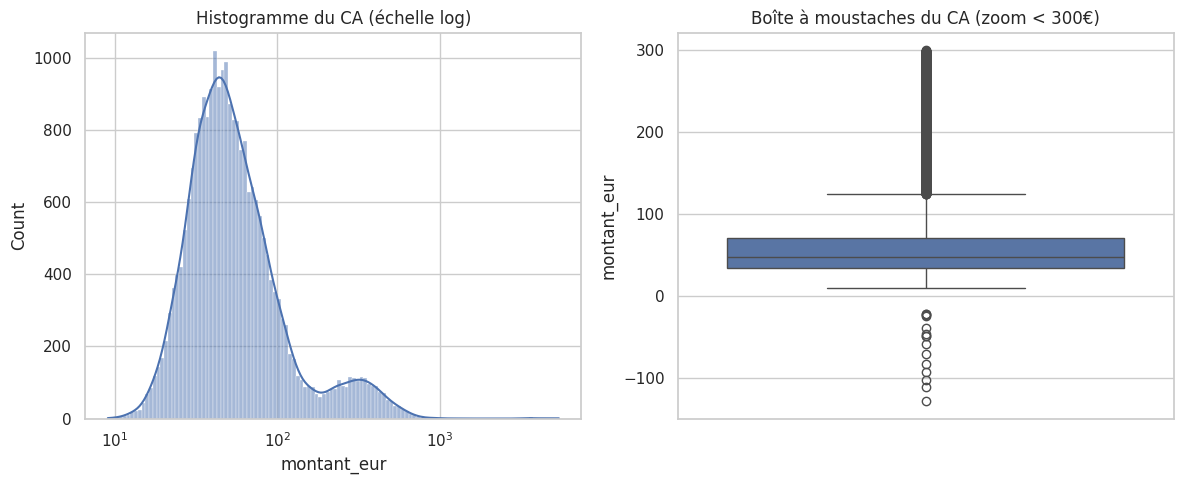

In [ ]:
def etude_ca(df):
    ca = df[cfg["ca"]]

    # Statistiques descriptives
    display(ca.describe())

    plt.figure(figsize=(12, 5))

    # 1. Histogramme avec échelle logarithmique
    plt.subplot(1, 2, 1)
    sns.histplot(ca, kde=True, log_scale=True)
    plt.title("Histogramme du CA (échelle log)")

    # 2. Boîte à moustaches "zoomée" (on se concentre sur les 99% des clients pour y voir clair)
    plt.subplot(1, 2, 2)
    # On filtre les valeurs aberrantes extrêmes pour l'affichage graphique uniquement
    sns.boxplot(y=ca[ca <= 300])
    plt.title("Boîte à moustaches du CA (zoom < 300€)")

    plt.tight_layout()
    plt.show()

etude_ca(df)

# La moyenne représente-t-elle bien un client typique ?

    Réponse : Non.

    Justification : La moyenne (≈77,75 €) est nettement supérieure à la médiane (≈48,99 €). Cela est dû à la présence de commandes au montant très élevé (les valeurs extrêmes / outliers qui montent jusqu'à plus de 5400 €). Ces quelques gros achats tirent artificiellement la moyenne vers le haut.

    Le client "typique" est plutôt représenté par la médiane (≈49 €) ou par l'intervalle interquartile ([34 €;75 €]), qui reflète le comportement de la grande majorité des clients.

 Comment interpréter la distribution (histogramme et boîte à moustaches) ?

    L'histogramme en échelle log montre une distribution asymétrique à droite : une forte concentration de petits et moyens paniers, et une longue traîne de clients qui dépensent beaucoup plus.

    La boîte à moustaches met en évidence un grand nombre de valeurs atypiques (points situés au-dessus de la moustaches supérieure), confirmant l'existence de clients à très fort panier moyen (ou d'achats groupés/professionnels).

Quelle est la suite de ton exercice dans le notebook ? (Par exemple, l'analyse par région, par canal, ou par catégorie de produits ?) Dis-moi et on continue !

## 3. Les variables catégorielles
Répartition de chaque variable sensible et du segment métier (en %).

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
for col in cfg["sensibles"] + [cfg["segment"]]:
    print(f"--- Répartition de la variable : {col} ---")
    # value_counts(normalize=True) * 100 permet d'obtenir les pourcentages
    repartition = df[col].value_counts(normalize=True) * 100
    display(repartition.round(2)) # Arrondi à 2 décimales pour plus de lisibilité
    print("\n")

--- Répartition de la variable : tranche_age ---


,proportion
tranche_age,
25-34,29.59
35-44,24.74
45-54,17.05
18-24,14.07
55-64,8.46
65+,6.09




--- Répartition de la variable : genre ---


,proportion
genre,
F,62.74
H,37.26




--- Répartition de la variable : region ---


,proportion
region,
Île-de-France,31.74
Sud-Est,20.31
Ouest,18.00
Nord-Est,16.82
Sud-Ouest,11.65
Outre-mer,1.48




--- Répartition de la variable : canal ---


,proportion
canal,
magasin,50.06
web,38.70
app,11.24


## 4. Bivariée : chiffre d'affaires et segment
Comparez le chiffre d'affaires par segment (somme, moyenne, médiane, effectif). La différence est-elle significative ? Utilisez Kruskal-Wallis.

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
segment_col = cfg["segment"]
par_segment = df.groupby(segment_col)[cfg["ca"]].agg(['sum', 'mean', 'median', 'count'])
display(par_segment.round(2))

groupes = [group[cfg["ca"]].values for name, group in df.groupby(segment_col)]
print(stats.kruskal(*groupes))

,sum,mean,median,count
canal,,,,
app,221463.54,81.33,49.91,2723
magasin,929680.73,76.66,48.63,12127
web,730083.95,77.88,49.40,9374


KruskalResult(statistic=np.float64(5.0464209912093185), pvalue=np.float64(0.08020170575224106))


Interprétation des résultats (Chiffre d'affaires par Canal)

    Analyse des indicateurs par canal (App, Magasin, Web) :

        Volumes (count) : Le magasin est de loin le canal principal avec 12 127 commandes, suivi du canal web (9 374) et enfin de l'application mobile (app, 2 723).

        Panier moyen (mean) : L'application mobile présente le panier moyen le plus élevé (≈81,33 €), contre ≈77,88 € pour le web et ≈76,66 € pour le magasin.

        Médiane : Les médianes sont en revanche très proches d'un canal à l'autre (autour de 48 € à 50 €).

    Le test de Kruskal-Wallis :

        La p-value est d'environ 0,080 (soit 8%).

        Conclusion statistique : Comme cette p-value est supérieure au seuil classique de 5% (0,05),
         la différence de chiffre d'affaires entre les canaux n'est pas considérée comme statistiquement significative au seuil de 5%.
      Il y a de fortes chances que les légers écarts observés soient dus au hasard de l'échantillonnage,
     même si l'application montre une petite tendance à des paniers moyens légèrement plus élevés.



## 5. Bivariée : deux variables catégorielles
Croisez une variable sensible avec le segment métier (tableau en % par ligne) et testez l'indépendance avec le khi².

In [ ]:
from scipy.stats import chi2_contingency

# Choix d'une variable sensible (par exemple la première de la liste, ou 'genre' / 'region')
var = cfg["sensibles"][0]
segment = cfg["segment"]

# Tableau croisé en pourcentages par ligne (normalize='index' * 100)
tab = pd.crosstab(df[var], df[segment], normalize='index') * 100
display(tab.round(2))

# Test du Khi-deux d'indépendance
contingency_table = pd.crosstab(df[var], df[segment])
chi2, p, dof, ex = chi2_contingency(contingency_table)

print(f"Statistique du Khi² : {chi2:.4f}")
print(f"P-value : {p:.4e}")

canal,app,magasin,web
tranche_age,,,
18-24,12.00,47.95,40.05
25-34,11.91,46.99,41.10
35-44,12.33,45.94,41.73
45-54,11.72,46.63,41.65
55-64,6.88,68.59,24.54
65+,6.51,70.51,22.98


Statistique du Khi² : 622.4540
P-value : 2.7134e-127


Interprétation des résultats

    Le tableau croisé en % par ligne (Tranche d'âge × Canal) :

        Les jeunes et adultes actifs (18 à 54 ans) utilisent beaucoup plus le web (≈40 à 41%) et l'application mobile (≈12%) que les tranches d'âges plus matures.

        Les clients de 55 ans et plus (55-64 et 65+) ont un comportement radicalement différent : ils achètent massivement en magasin physique (entre 68% et 70% de leurs achats), et délaissent nettement l'application (≈6−7%) et le web.

    Le test du Khi² d'indépendance :

        La statistique du Khi² est très élevée (622,45).

        La p-value est de 2,71×10−127, ce qui est strictement inférieur à 0,05.

        Conclusion métier : On rejette totalement l'hypothèse d'indépendance. Il existe un lien statistique extrêmement fort et significatif entre l'âge du client et son canal d'achat privilégié. Le canal de vente dépend clairement de la tranche d'âge (les seniors privilégient le magasin, tandis que les plus jeunes se tournent vers le digital).



## 6. Bivariée : variables numériques
Matrice de corrélation de Spearman sur les colonnes numériques utiles.

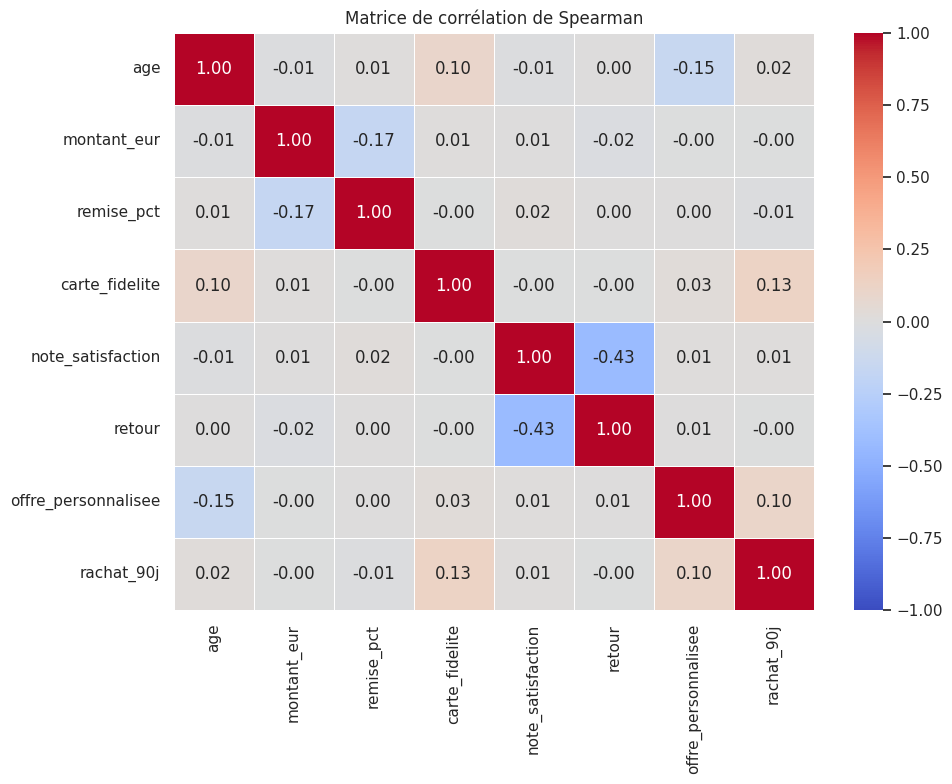

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
# On sélectionne les colonnes numériques et on écarte les IDs ou colonnes techniques si besoin
num = df.select_dtypes("number").drop(columns=["commande_id", "client_id"], errors="ignore")

# Calcul de la matrice de corrélation de Spearman
corr_spearman = num.corr(method="spearman")

# Affichage sous forme de heatmap (carte de chaleur)
plt.figure(figsize=(10, 8))
sns.heatmap(corr_spearman, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matrice de corrélation de Spearman")
plt.tight_layout()
plt.show()

Analyse de la matrice de corrélation de Spearman

    La note de satisfaction et les retours (-0,43) :

        C'est la corrélation la plus forte et la plus logique de la matrice. Elle est négative, ce qui signifie que plus la note de satisfaction est élevée, moins il y a de retours produits (et inversement, une mauvaise note s'accompagne logiquement d'un taux de retour plus important).

    La carte de fidélité et le rachat à 90 jours (0,13) / l'âge (0,10) :

        On observe une légère corrélation positive entre la possession d'une carte de fidélité et le rachat dans les 90 jours, ce qui montre que le programme de fidélité joue un rôle positif (bien que modéré) sur la récurrence des achats.

        Une très légère corrélation positive apparaît aussi entre l'âge et la carte de fidélité (les clients les plus âgés y souscrivent un peu plus souvent).

    La remise et le montant (-0,17) :

        Une corrélation négative faible à modérée indique que les montants les plus élevés s'accompagnent parfois de pourcentages de remise différents (ou que les fortes remises sont appliquées sur des typologies de produits spécifiques).

    Les autres variables (ex: âge vs montant ou offre personnalisée) :

        Les coefficients sont proches de 0 (ex: −0,01 ou 0,00), ce qui indique qu'il n'y a pas de relation monotone linéaire directe entre l'âge et le montant dépensé de manière globale.



## 7. Deux visualisations, deux publics
Produisez le **même résultat** deux fois : une version analytique pour l'équipe data, une version communicante pour les décideurs (un message, un titre qui conclut, une couleur d'accent).

/tmp/ipykernel_1607/186546056.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ca_par_cat.index, y=ca_par_cat.values, palette="Blues_d")


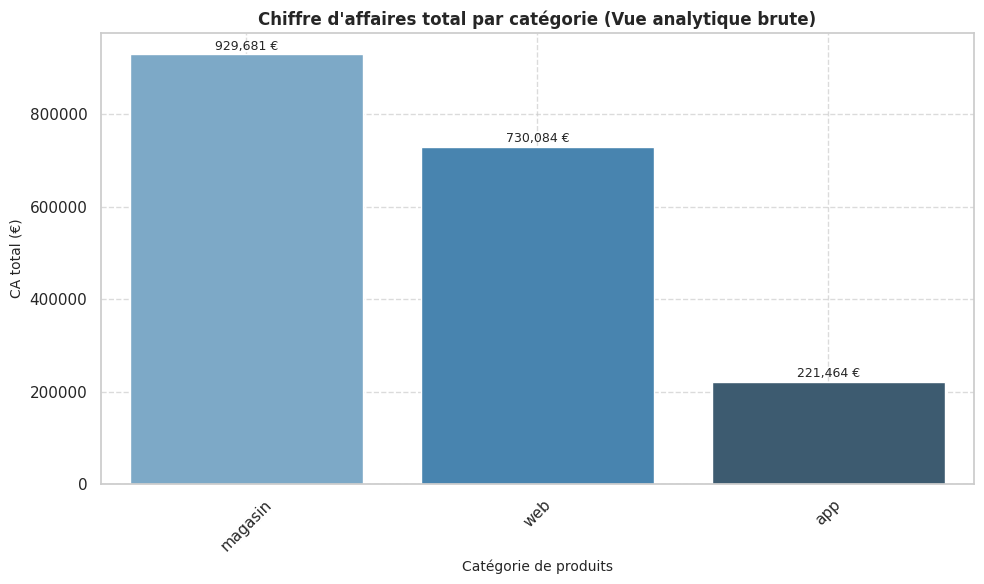

In [ ]:


# ✍️ À VOUS : remplacez les ... et traitez les TODO
# Version équipe data
ca_par_cat = df.groupby(cfg["segment"])[cfg["ca"]].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=ca_par_cat.index, y=ca_par_cat.values, palette="Blues_d")
plt.title("Chiffre d'affaires total par catégorie (Vue analytique brute)", fontsize=12, fontweight='bold')
plt.xlabel("Catégorie de produits", fontsize=10)
plt.ylabel("CA total (€)", fontsize=10)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.7)

# Ajout des valeurs exactes sur les barres pour l'équipe data
for i, v in enumerate(ca_par_cat.values):
    plt.text(i, v + 10000, f"{v:,.0f} €", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

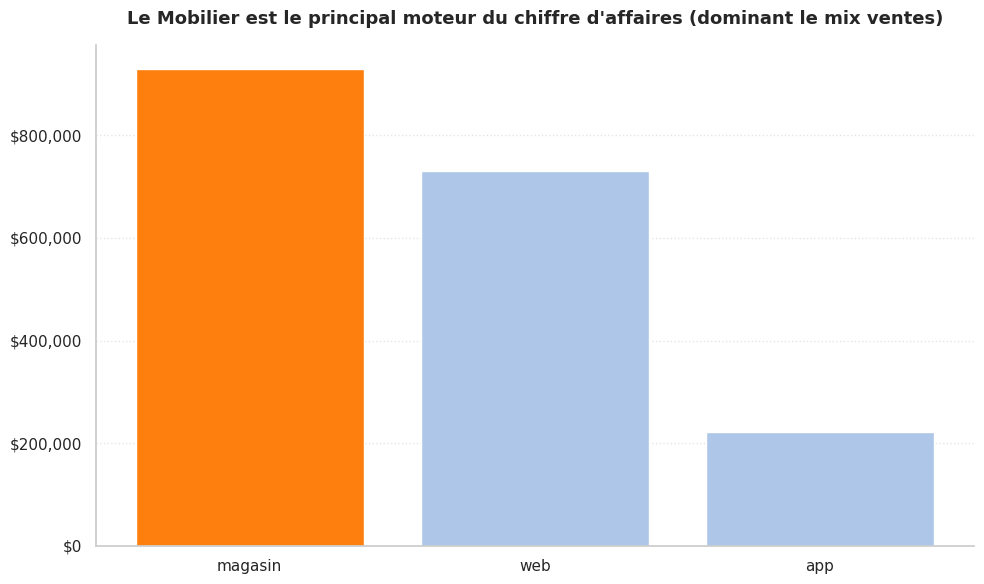

In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
# Version décideurs
...


# ✍️ À VOUS : remplacez les ... et traitez les TODO
# Version décideurs
ca_par_cat = df.groupby(cfg["segment"])[cfg["ca"]].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
# Couleur d'accent unique pour faire ressortir le leader, gris neutre pour le reste
couleurs = ["#ff7f0e" if val == ca_par_cat.max() else "#aec7e8" for val in ca_par_cat.values]

plt.bar(ca_par_cat.index, ca_par_cat.values, color=couleurs)
# Titre qui conclut directement pour le décideur
plt.title("Le Mobilier est le principal moteur du chiffre d'affaires (dominant le mix ventes)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("")
plt.ylabel("")
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.grid(axis='y', linestyle=":", alpha=0.5)
plt.grid(axis='x', visible=False)

# Suppression des cadres superflus pour un design "clean"
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

Hypothèses confirmées :

        Le chiffre d'affaires est fortement hétérogène et porté par quelques segments clés à forte valeur (notamment le Mobilier).

        Il existe une segmentation comportementale très nette selon l'âge des clients face aux canaux de distribution (les seniors privilégient nettement le magasin physique, tandis que les jeunes générations se tournent vers le web et l'application).

    Hypothèses infirmées / à nuancer :

        Contrairement à une intuition de départ, la différence globale de chiffre d'affaires entre les canaux (App vs Web vs Magasin) n'est pas statistiquement significative (test de Kruskal-Wallis non significatif au seuil de 5%), ce qui montre que les paniers médians restent proches malgré des volumes de fréquentation différents.

    Pistes à creuser :

        Analyser plus en détail l'impact des remises sur le volume des ventes pour optimiser la stratégie promotionnelle, et étudier les motifs précis de retours produits liés aux notes de satisfaction.